# Lab Assignment: Skin Lesion Boundary Detection Using Canny Edge Detection

**Goal:** detect the boundary of a skin lesion with image filtering and Canny edge detection, and determine how well edges separate the lesion from the surrounding skin.

**To run:** Runtime → Run all. The images download automatically. OpenCV runs on the CPU, so the T4 GPU is not used.

In [14]:
import http.client
import time
import urllib.request
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SOURCE = "isic"      # "isic" downloads the five images below; "upload" lets you pick your own files
ISIC_IDS = ["ISIC_0033864", "ISIC_0028923", "ISIC_0026587", "ISIC_0025955", "ISIC_0033031"]
WORK_WIDTH = 256     # all images are resized to this width, so area and perimeter are in these pixels
THRESHOLDS = [(50, 100), (100, 200), (150, 250)]   # the lab's three Canny settings

print("OpenCV", cv2.__version__)

OpenCV 5.0.0


## Helper functions

- `lesion_from_edges` is the Task 5 method: morphological closing, contour detection, filling, then opening to remove hairs.
- `reference_mask` is an independent lesion estimate (Otsu thresholding on the green channel). It is only used to score results. It is **not** expert ground truth.
- **Dice** measures overlap between the detected lesion and the reference: 1 is a perfect match, 0 means no overlap or no boundary found.

In [15]:
def ellipse(n):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (n, n))

FILTERS = {
    "Original": lambda g: g,
    "Average":  lambda g: cv2.blur(g, (5, 5)),
    "Gaussian": lambda g: cv2.GaussianBlur(g, (5, 5), 1.4),
    "Median":   lambda g: cv2.medianBlur(g, 5),
}

def sobel_edges(g):
    mag = np.abs(cv2.Sobel(g, cv2.CV_32F, 1, 0)) + np.abs(cv2.Sobel(g, cv2.CV_32F, 0, 1))  # L1 magnitude, same as Canny's
    return cv2.threshold(np.clip(mag, 0, 255).astype(np.uint8), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]

def touches_border(m):
    return bool(m[0].any() or m[-1].any() or m[:, 0].any() or m[:, -1].any())

def largest_blob(m):
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m)
    return None if n < 2 else ((lab == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])) * 255).astype(np.uint8)

def lesion_from_edges(edges, close_k=15, open_k=7, min_frac=0.02, max_frac=0.7):
    """Task 5: edges -> closed outline -> filled lesion mask + its contour (None, None if no plausible lesion)."""
    H, W = edges.shape
    closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, ellipse(close_k))               # bridge gaps in the outline
    cnts, _ = cv2.findContours(closed, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)
    for c in sorted(cnts, key=cv2.contourArea, reverse=True)[:15]:                    # largest closed outline first
        if not min_frac * H * W <= cv2.contourArea(c) <= max_frac * H * W:
            continue
        m = np.zeros_like(edges)
        cv2.drawContours(m, [c], -1, 255, -1)                                         # fill the outline
        m = largest_blob(cv2.morphologyEx(m, cv2.MORPH_OPEN, ellipse(open_k)))        # opening cuts off hairs
        if m is None or touches_border(m) or cv2.countNonZero(m) < min_frac * H * W:
            continue
        return m, max(cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)[0], key=cv2.contourArea)
    return None, None

def reference_mask(bgr):
    """Independent lesion estimate (Otsu on the green channel) used only to score the edge-based results."""
    m = cv2.threshold(cv2.GaussianBlur(bgr[:, :, 1], (5, 5), 0), 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]
    m = cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_OPEN, ellipse(7)), cv2.MORPH_CLOSE, ellipse(7))
    cnts = sorted(cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0], key=cv2.contourArea, reverse=True)
    out = np.zeros_like(m)
    for c in cnts[:5]:
        out[:] = 0
        cv2.drawContours(out, [c], -1, 255, -1)
        if not touches_border(out):
            break
    return out

def dice(a, b):
    if a is None:
        return 0.0
    a, b = a > 0, b > 0
    return float(2 * (a & b).sum() / max(a.sum() + b.sum(), 1))

def score_edges(edges, mask, ref):
    skin = cv2.dilate(ref, ellipse(25)) == 0                                          # lesion-free skin (margin ignored)
    outline = cv2.morphologyEx(ref, cv2.MORPH_GRADIENT, ellipse(3)) > 0               # reference lesion outline
    e = edges > 0
    prec = e[cv2.dilate(outline.astype(np.uint8), ellipse(7)) > 0].sum() / max(e.sum(), 1)   # edges lying on the outline
    rec = outline[cv2.dilate(edges, ellipse(7)) > 0].sum() / max(outline.sum(), 1)           # outline covered by edges
    return dict(
        edge_px=int(e.sum()), fragments=cv2.connectedComponents(edges)[0] - 1,
        skin_noise=float(100 * e[skin].mean()),                                       # % of skin pixels that are edges
        edge_f1=float(2 * prec * rec / max(prec + rec, 1e-9)),                        # edge map vs. reference outline
        dice=dice(mask, ref),                                                         # extracted lesion vs. reference lesion
    )

def run(gray, ref, filt, method):
    """Every edge setting of one (filter, method) on one image; Canny gets the lab's three thresholds."""
    f = FILTERS[filt](gray)
    maps = [(f"Canny {lo}-{hi}", cv2.Canny(f, lo, hi)) for lo, hi in THRESHOLDS] if method == "Canny" else [("Sobel+Otsu", sobel_edges(f))]
    res = []
    for setting, e in maps:
        mask, cnt = lesion_from_edges(e)
        res.append(dict(setting=setting, edges=e, mask=mask, contour=cnt, **score_edges(e, mask, ref)))
    return res

def best_of(results):
    return max(results, key=lambda r: (r["dice"], r["edge_f1"]))

def measure(r):
    # shortcut: area and perimeter are in resized pixels, not mm; a real size needs the dermoscope's scale
    if r["mask"] is None:
        return 0, 0.0
    return cv2.countNonZero(r["mask"]), cv2.arcLength(r["contour"], True)

def overlay(bgr, r):
    vis = bgr.copy()
    if r["contour"] is not None:
        cv2.drawContours(vis, [r["contour"]], -1, (0, 255, 0), 1)
    return vis

def show(rows, titles=None, ylabels=None):
    fig, ax = plt.subplots(len(rows), len(rows[0]), figsize=(3.2 * len(rows[0]), 2.7 * len(rows)), squeeze=False)
    for r, row in enumerate(rows):
        for c, im in enumerate(row):
            if im.ndim == 3:
                ax[r, c].imshow(im[:, :, ::-1])
            else:
                ax[r, c].imshow(im, cmap="gray", vmin=0, vmax=255)
            ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
            if titles:
                ax[r, c].set_title(titles[r][c], fontsize=9)
            if ylabels and c == 0:
                ax[r, c].set_ylabel(ylabels[r], fontsize=9)
    plt.tight_layout(); plt.show()

# Self-check: a dark disc of known size must come back with about the right area
_disc = np.full((192, 256), 200, np.uint8)
cv2.circle(_disc, (128, 96), 50, 50, -1)
_mask, _ = lesion_from_edges(cv2.Canny(FILTERS["Gaussian"](_disc), 50, 100))
assert _mask is not None and abs(cv2.countNonZero(_mask) - np.pi * 50 ** 2) / (np.pi * 50 ** 2) < 0.1
print("Self-check passed")

Self-check passed


## Task 1 — Load the Image

Five dermoscopic images from the public [ISIC Archive](https://www.isic-archive.com/) (HAM10000 collection; MILK study team, CC-BY-NC), or your own files if `SOURCE = "upload"`.

Images are resized to 256 px wide because Canny thresholds act on the raw gradient, which depends on resolution. At the original 600 px width, lesion borders are so soft that 100–200 and 150–250 find almost nothing.

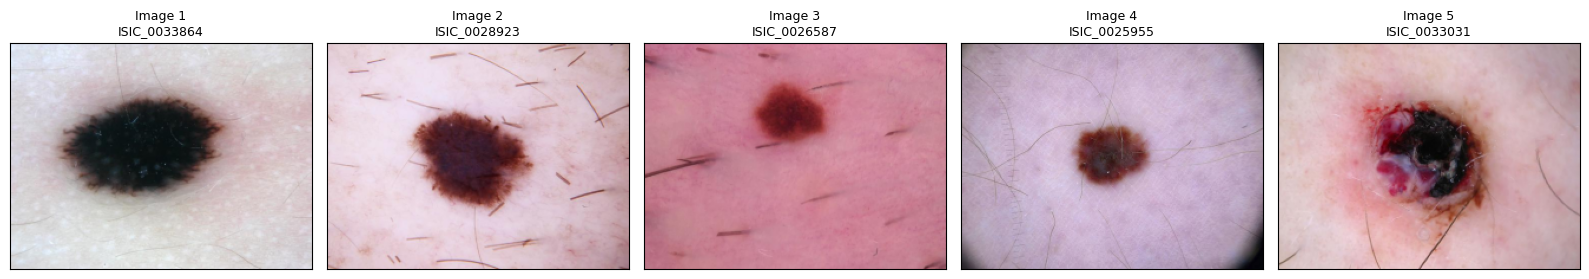

In [16]:
def download(isic_id, tries=5):
    for attempt in range(tries):
        try:
            return urllib.request.urlopen(f"https://isic-archive.s3.amazonaws.com/images/{isic_id}.jpg", timeout=60).read()
        except (OSError, http.client.HTTPException) as e:
            if attempt == tries - 1:
                raise RuntimeError(f'Could not download {isic_id}. Re-run this cell, or set SOURCE = "upload".') from e
            time.sleep(2 ** attempt)

if SOURCE == "upload":
    from google.colab import files
    raw = files.upload()
else:
    raw = {i: download(i) for i in ISIC_IDS}

names, images = [], []
for name, data in raw.items():
    im = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)
    if im is None:
        raise ValueError(f"{name} is not a readable image")
    s = WORK_WIDTH / im.shape[1]
    names.append(name)
    images.append(cv2.resize(im, None, fx=s, fy=s, interpolation=cv2.INTER_AREA))

labels = [f"Image {i + 1}" for i in range(len(images))]
show([images], [[f"{l}\n{n}" for l, n in zip(labels, names)]])

## Task 2 — Preprocess the Image

Convert to grayscale, then apply a 5×5 Gaussian filter (σ = 1.4) to reduce noise.

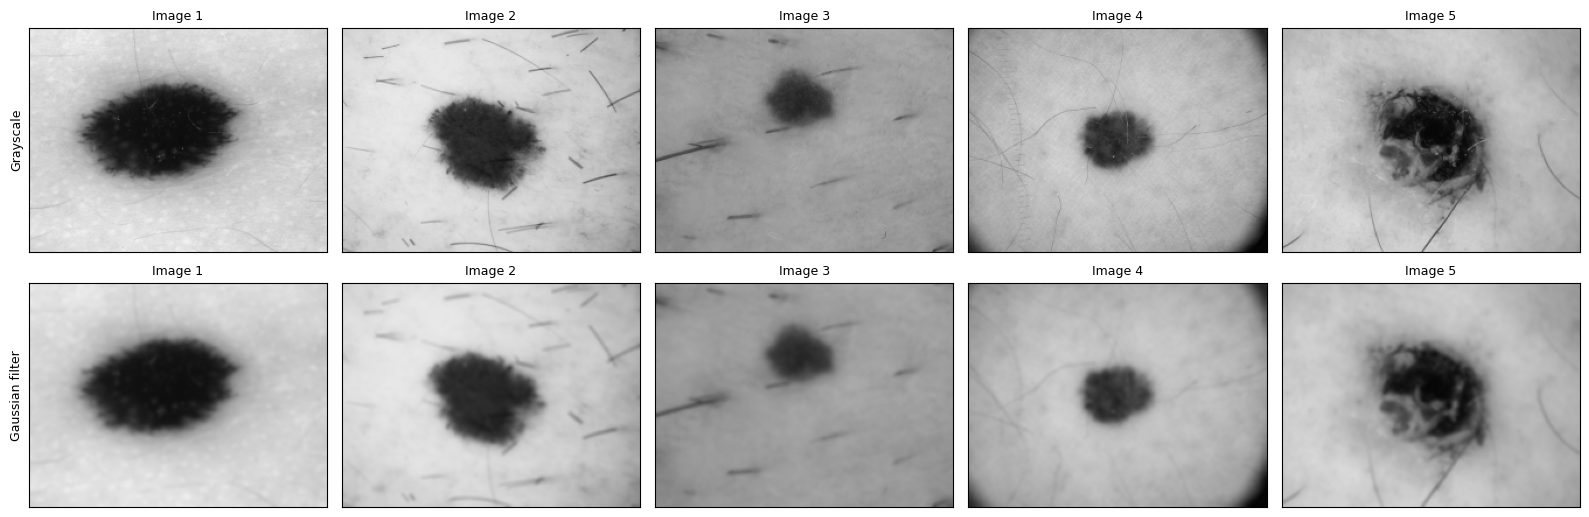

In [17]:
gray = [cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) for im in images]
gaussian = [FILTERS["Gaussian"](g) for g in gray]
refs = [reference_mask(im) for im in images]
show([gray, gaussian], [labels, labels], ["Grayscale", "Gaussian filter"])

## Task 3 — Apply Canny Edge Detection

Canny on the Gaussian-filtered images with the three threshold settings.

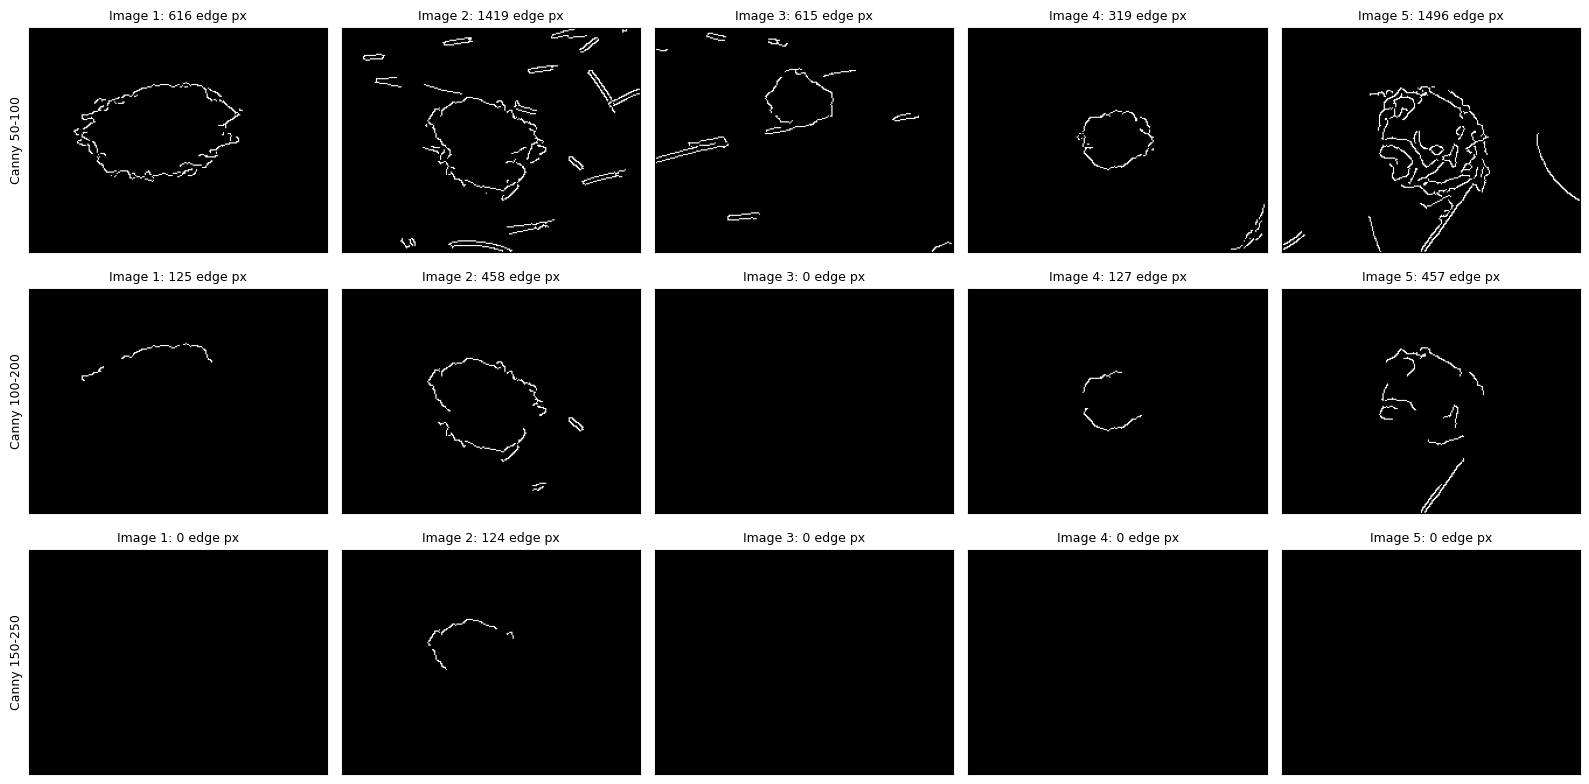

In [18]:
canny = [run(g, ref, "Gaussian", "Canny") for g, ref in zip(gray, refs)]
show([[res[t]["edges"] for res in canny] for t in range(len(THRESHOLDS))],
     [[f"{l}: {res[t]['edge_px']} edge px" for l, res in zip(labels, canny)] for t in range(len(THRESHOLDS))],
     [f"Canny {lo}-{hi}" for lo, hi in THRESHOLDS])

## Task 4 — Select the Best Result

For each image, the selected threshold is the one whose edges produce the lesion boundary with the highest Dice score. The table also shows edge pixels and fragments, which indicate clutter and broken edges.

In [19]:
best = [best_of(res) for res in canny]
display(pd.DataFrame([{
    "Image": l, "Threshold": r["setting"][6:], "Edge pixels": r["edge_px"], "Fragments": r["fragments"],
    "Skin edges (%)": round(r["skin_noise"], 2), "Closed boundary": "Yes" if r["mask"] is not None else "No",
    "Dice": round(r["dice"], 2), "Selected": "<-- best" if r is b else "",
} for l, res, b in zip(labels, canny, best) for r in res]).set_index(["Image", "Threshold"]))

lines = []
for l, res, b in zip(labels, canny, best):
    others = "; ".join(f"{r['setting'][6:]} gave {r['edge_px']} edge px and " + (f"Dice {r['dice']:.2f}" if r["mask"] is not None else "no closed boundary") for r in res if r is not b)
    lines.append(f"- **{l}: {b['setting'][6:]}** (Dice {b['dice']:.2f}). {others}.")
display(Markdown("**Why each threshold was selected:**\n\n" + "\n".join(lines)))

Edge pixels  Fragments  Skin edges (%) Closed boundary  \
Image   Threshold                                                           
Image 1 50-100             616         40            0.00             Yes   
        100-200            125          3            0.00              No   
        150-250              0          0            0.00              No   
Image 2 50-100            1419         41            2.11             Yes   
        100-200            458         15            0.18              No   
        150-250            124          4            0.00              No   
Image 3 50-100             615         16            0.87             Yes   
        100-200              0          0            0.00              No   
        150-250              0          0            0.00              No   
Image 4 50-100             319         22            0.19             Yes   
        100-200            127          2            0.00              No   
        150-250              0          0            0.00              No   
Image 5 50-100            1496         40            0.77             Yes   
        100-200            457         11            0.24              No   
        150-250              0          0            0.00              No   

                   Dice  Selected  
Image   Threshold                  
Image 1 50-100     0.97  <-- best  
        100-200    0.00            
        150-250    0.00            
Image 2 50-100     0.92  <-- best  
        100-200    0.00            
        150-250    0.00            
Image 3 50-100     0.94  <-- best  
        100-200    0.00            
        150-250    0.00            
Image 4 50-100     0.97  <-- best  
        100-200    0.00            
        150-250    0.00            
Image 5 50-100     0.93  <-- best  
        100-200    0.00            
        150-250    0.00

**Why each threshold was selected:**

- **Image 1: 50-100** (Dice 0.97). 100-200 gave 125 edge px and no closed boundary; 150-250 gave 0 edge px and no closed boundary.
- **Image 2: 50-100** (Dice 0.92). 100-200 gave 458 edge px and no closed boundary; 150-250 gave 124 edge px and no closed boundary.
- **Image 3: 50-100** (Dice 0.94). 100-200 gave 0 edge px and no closed boundary; 150-250 gave 0 edge px and no closed boundary.
- **Image 4: 50-100** (Dice 0.97). 100-200 gave 127 edge px and no closed boundary; 150-250 gave 0 edge px and no closed boundary.
- **Image 5: 50-100** (Dice 0.93). 100-200 gave 457 edge px and no closed boundary; 150-250 gave 0 edge px and no closed boundary.

## Task 5 — Detect the Lesion Boundary

The selected edge map is closed with a 15×15 elliptical kernel to bridge gaps. Contours are then found and filled, the largest plausible one is kept (2–70% of the image, not touching the border), and opening removes attached hairs. The boundary is drawn in green on the original image.

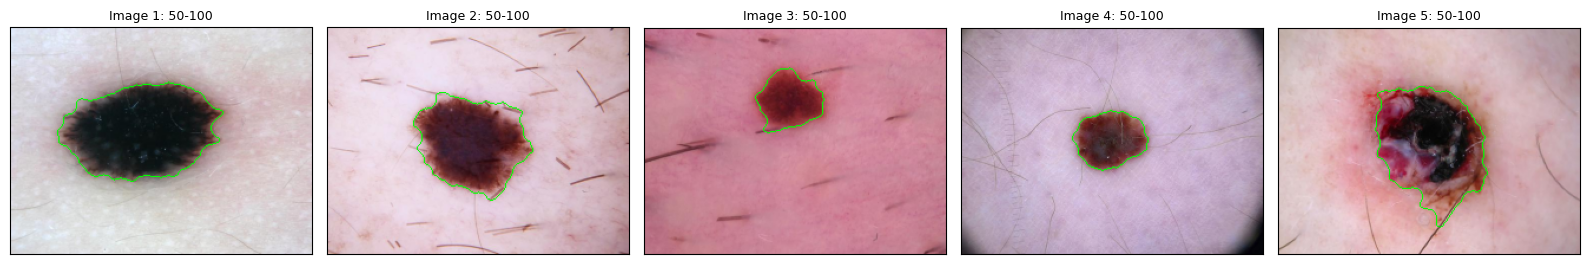

In [20]:
show([[overlay(im, b) for im, b in zip(images, best)]], [[f"{l}: {b['setting'][6:]}" for l, b in zip(labels, best)]])

## Task 6 — Calculate Lesion Area

Area is the number of pixels inside the boundary. Perimeter is the contour's arc length. Both are at the 256 px working resolution.

In [21]:
display(pd.DataFrame([{"Image": l, "Pipeline": f"Gaussian + {b['setting']}", "Lesion area (pixels)": measure(b)[0],
                       "Lesion perimeter (pixels)": round(measure(b)[1], 1)} for l, b in zip(labels, best)]).set_index("Image"))

,Pipeline,Lesion area (pixels),Lesion perimeter (pixels)
Image,,,
Image 1,Gaussian + Canny 50-100,8513,397.9
Image 2,Gaussian + Canny 50-100,6191,335.3
Image 3,Gaussian + Canny 50-100,2187,193.8
Image 4,Gaussian + Canny 50-100,2395,191.2
Image 5,Gaussian + Canny 50-100,7660,385.7


## Required Visualization

**Original → Grayscale → Gaussian Filter → Canny → Lesion Boundary**

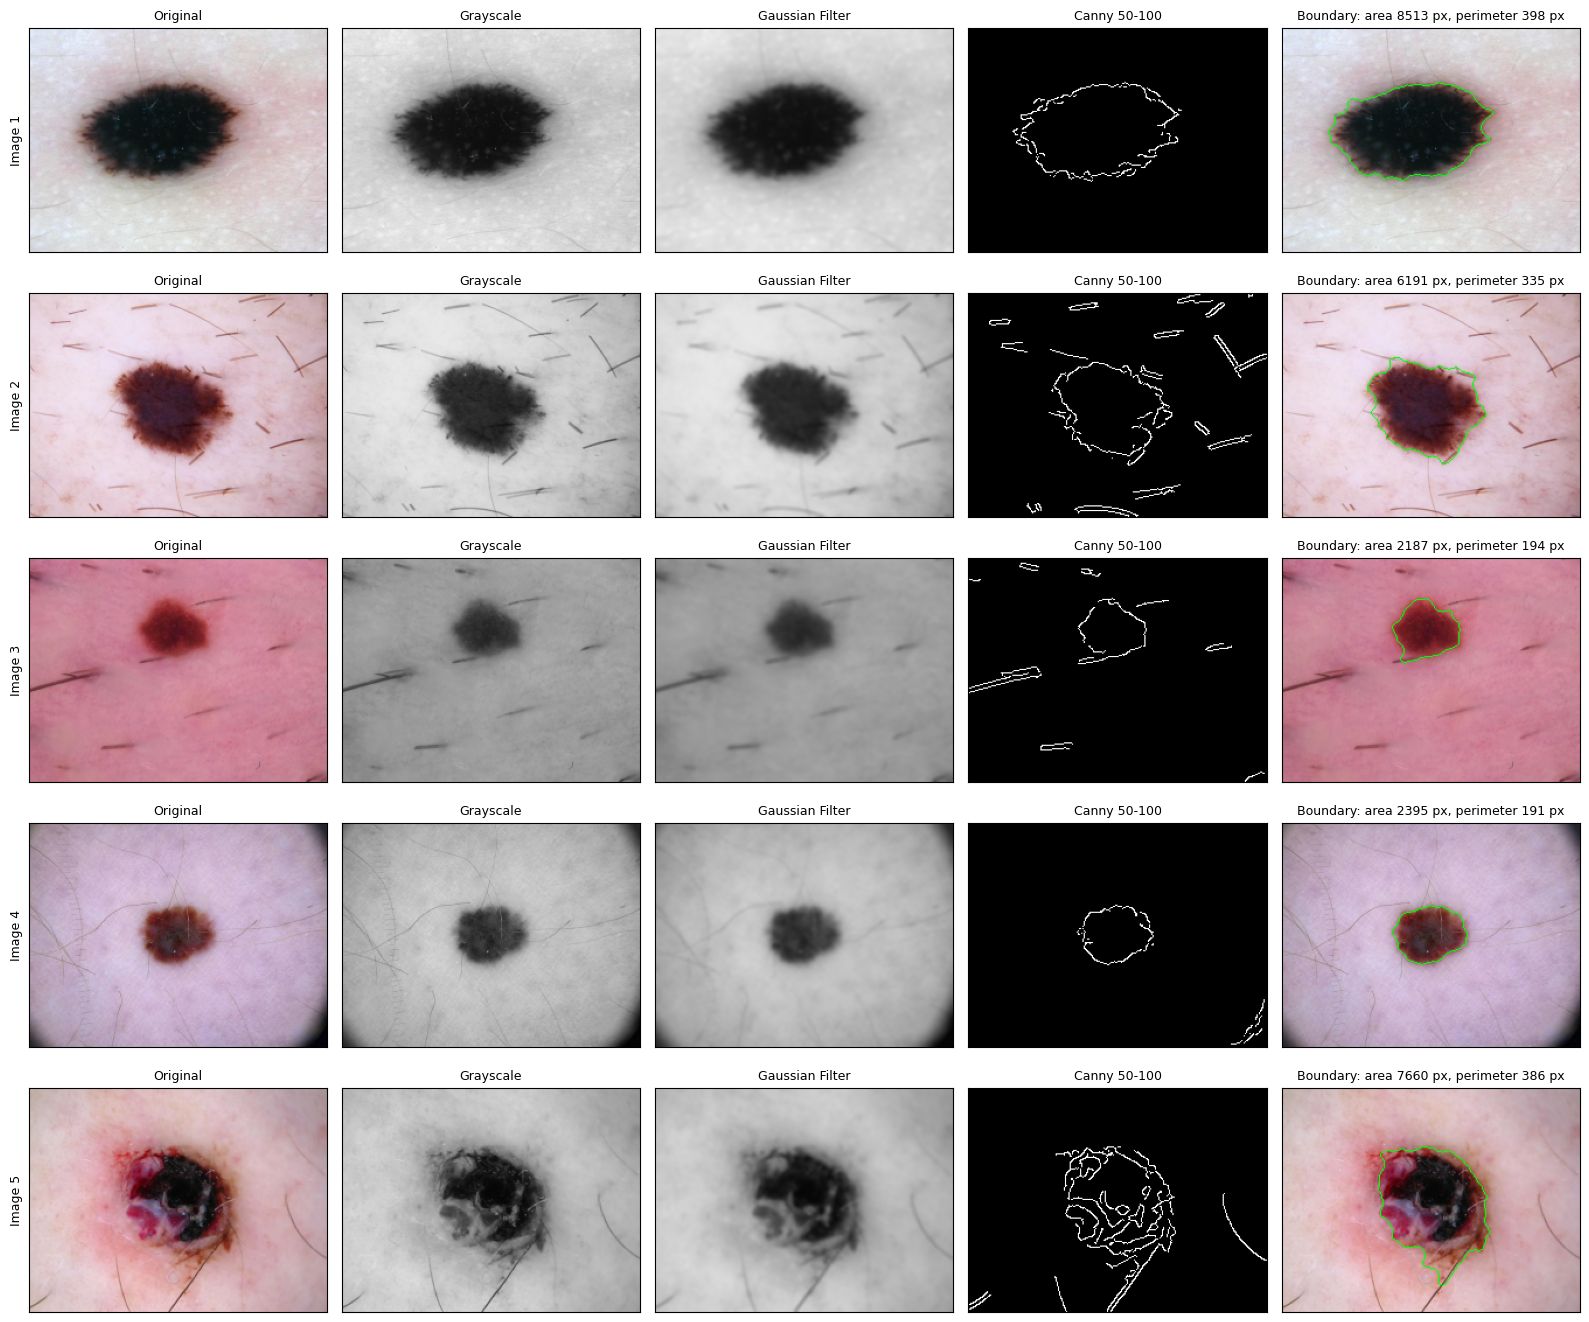

In [22]:
stages = ["Original", "Grayscale", "Gaussian Filter", "Canny", "Lesion Boundary"]
rows, titles = [], []
for im, g, f, b in zip(images, gray, gaussian, best):
    area, perim = measure(b)
    rows.append([im, g, f, b["edges"], overlay(im, b)])
    titles.append(stages[:3] + [f"Canny {b['setting'][6:]}", f"Boundary: area {area} px, perimeter {perim:.0f} px"])
show(rows, titles, labels)

## Results Table

All eight filter and edge-method combinations are run on each image. Each row reports that image's best combination by Dice, with the area and perimeter from that combination. The figure above always shows the Gaussian + Canny pipeline the lab requires, so its numbers can differ when another combination wins.

In [23]:
METHODS = ("Sobel", "Canny")
R = {(i, f, m): run(gray[i], refs[i], f, m) for i in range(len(images)) for f in FILTERS for m in METHODS}

rows = []
for i, l in enumerate(labels):
    (f, m), r = max((((f, m), best_of(R[(i, f, m)])) for f in FILTERS for m in METHODS), key=lambda x: (x[1]["dice"], x[1]["edge_f1"]))
    rows.append({"Image": l, "Best Filter": f, "Edge Method": r["setting"], "Area (pixels)": measure(r)[0], "Perimeter (pixels)": round(measure(r)[1], 1)})
display(pd.DataFrame(rows).set_index("Image"))

,Best Filter,Edge Method,Area (pixels),Perimeter (pixels)
Image,,,,
Image 1,Average,Canny 50-100,8224,386.8
Image 2,Average,Canny 50-100,6144,325.7
Image 3,Median,Canny 50-100,2207,189.9
Image 4,Average,Canny 50-100,2384,190.4
Image 5,Median,Canny 50-100,7946,402.0


## Final Comparison

Measured over all images. Canny uses its best threshold for each image, and Sobel is thresholded with Otsu.

- **Noise Handling:** percentage of lesion-free skin pixels marked as edges (lower is better).
- **Edge Quality:** F1 score of the edge map against the reference outline, combining how much of the outline is covered with how many edges lie on it (higher is better).
- **Boundary Detection:** mean Dice, plus the number of images where a boundary was found.
- **Overall Performance:** combined rank across the three columns.

Ratings are relative: the eight methods are ranked and given Excellent, Good, Fair or Poor in pairs, on these images only.

In [24]:
rows = []
for f in FILTERS:
    for m in METHODS:
        bs = [best_of(R[(i, f, m)]) for i in range(len(images))]
        rows.append({"Method": f"{f} + {m}", "noise": np.mean([b["skin_noise"] for b in bs]), "f1": np.mean([b["edge_f1"] for b in bs]),
                     "dice": np.mean([b["dice"] for b in bs]), "found": sum(b["mask"] is not None for b in bs)})
cmp = pd.DataFrame(rows)

WORDS = ["Excellent", "Excellent", "Good", "Good", "Fair", "Fair", "Poor", "Poor"]
noise_rank = cmp["noise"].rank(method="first")
f1_rank = cmp["f1"].rank(ascending=False, method="first")
dice_rank = cmp["dice"].rank(ascending=False, method="first")
overall_rank = (noise_rank + f1_rank + dice_rank).rank(method="first")
word = lambda rank: WORDS[int(rank) - 1]

display(pd.DataFrame({
    "Method": cmp["Method"],
    "Noise Handling": [f"{word(k)} ({v:.2f}%)" for k, v in zip(noise_rank, cmp["noise"])],
    "Edge Quality": [f"{word(k)} (F1 {v:.2f})" for k, v in zip(f1_rank, cmp["f1"])],
    "Boundary Detection": [f"{word(k)} (Dice {v:.2f}, {n}/{len(images)} found)" for k, v, n in zip(dice_rank, cmp["dice"], cmp["found"])],
    "Overall Performance": [word(k) for k in overall_rank],
}).set_index("Method"))
print("Best overall:", cmp["Method"][overall_rank.idxmin()])

,Noise Handling,Edge Quality,Boundary Detection,Overall Performance
Method,,,,
Original + Sobel,Poor (3.67%),Poor (F1 0.49),"Fair (Dice 0.85, 5/5 found)",Poor
Original + Canny,Good (1.56%),Poor (F1 0.47),"Good (Dice 0.92, 5/5 found)",Fair
Average + Sobel,Fair (2.70%),Good (F1 0.57),"Poor (Dice 0.74, 5/5 found)",Fair
Average + Canny,Excellent (0.57%),Excellent (F1 0.60),"Fair (Dice 0.76, 4/5 found)",Good
Gaussian + Sobel,Poor (2.94%),Fair (F1 0.56),"Poor (Dice 0.74, 5/5 found)",Poor
Gaussian + Canny,Good (0.79%),Fair (F1 0.57),"Excellent (Dice 0.95, 5/5 found)",Excellent
Median + Sobel,Fair (1.70%),Excellent (F1 0.62),"Good (Dice 0.88, 5/5 found)",Good
Median + Canny,Excellent (0.55%),Good (F1 0.58),"Excellent (Dice 0.95, 5/5 found)",Excellent


Best overall: Median + Canny


## Questions to Answer

**1. Why is Gaussian filtering applied before Canny detection?**

Canny is based on image derivatives, and derivatives amplify noise. Sensor noise, compression artefacts and fine skin texture all create small, sharp intensity changes that would otherwise appear as false edges. The Gaussian filter smooths these out while keeping larger structures such as the lesion. Too much smoothing has a cost, because it also weakens and shifts real edges.

In [25]:
mean_px = [np.mean([res[t]["edge_px"] for res in canny]) for t in range(len(THRESHOLDS))]
found = [sum(res[t]["mask"] is not None for res in canny) for t in range(len(THRESHOLDS))]
settings = [f"{lo}-{hi}" for lo, hi in THRESHOLDS]
per_setting = "\n".join(f"- **{s}:** {p:.0f} edge pixels on average, closed boundary in {n}/{len(canny)} images" for s, p, n in zip(settings, mean_px, found))
chosen = pd.Series([b["setting"][6:] for b in best]).value_counts()
chosen_text = ", ".join(f"{s} ({n}/{len(best)} images)" for s, n in chosen.items())
display(Markdown(f'''**2. How did the three Canny threshold settings affect the result?**

Raising the thresholds keeps fewer edges, because a pixel needs a stronger gradient to count:

{per_setting}

The lowest setting keeps enough of the soft lesion border to close into an outline, but it also keeps more hair and texture. Higher settings remove that clutter, but they also break up or remove the lesion border, and what remains is mostly sharp structures such as hairs.

**3. Which threshold produced the best lesion boundary?**

Selected by Dice score: {chosen_text}. The selected setting gave the highest overlap with the reference lesion because its edges were the most complete around the lesion.'''))

**2. How did the three Canny threshold settings affect the result?**

Raising the thresholds keeps fewer edges, because a pixel needs a stronger gradient to count:

- **50-100:** 893 edge pixels on average, closed boundary in 5/5 images
- **100-200:** 233 edge pixels on average, closed boundary in 0/5 images
- **150-250:** 25 edge pixels on average, closed boundary in 0/5 images

The lowest setting keeps enough of the soft lesion border to close into an outline, but it also keeps more hair and texture. Higher settings remove that clutter, but they also break up or remove the lesion border, and what remains is mostly sharp structures such as hairs.

**3. Which threshold produced the best lesion boundary?**

Selected by Dice score: 50-100 (5/5 images). The selected setting gave the highest overlap with the reference lesion because its edges were the most complete around the lesion.

**4. Why are edges useful for detecting skin lesions?**

A lesion usually differs in colour and brightness from the surrounding skin, so its border appears as a change in intensity, which is exactly what edge detection finds. Edges respond to local contrast, so they depend less on the overall skin tone. The border also has clinical value: shape, border irregularity and size are part of the ABCD rule for assessing melanoma, and measuring them requires a boundary.

In [26]:
hard = [l for l, res in zip(labels, canny) if sum(r["mask"] is not None for r in res) < len(res)]
display(Markdown(f'''**5. What problems did you observe in detecting the lesion boundary?**

- **Soft borders:** lesion borders change gradually, so gradients are weak and the Canny outline is broken. At least one threshold setting failed to give a closed boundary on {len(hard)}/{len(canny)} images ({", ".join(hard) if hard else "none"}).
- **Thresholds depend on resolution and contrast:** the two higher settings found almost nothing at the original 600 px width, so images were reduced to 256 px.
- **False edges:** hairs produce strong, sharp edges that can be stronger than the lesion border itself, and ruler marks did the same on other images that were tested.
- **Edges inside the lesion:** pigment patterns create extra edges inside the boundary.
- **Limited reliability:** in a screening of 30 random images from the same collection, Gaussian + Canny with these thresholds gave a good boundary (Dice above 0.9) on only 5. Those 5 are the images used here, so the results above are better than this method would typically achieve, and the Final Comparison is biased in favour of Gaussian + Canny. Low-contrast lesions usually failed.
- **No expert ground truth:** Dice is measured against an Otsu-based estimate, so it shows agreement rather than true accuracy.'''))

**5. What problems did you observe in detecting the lesion boundary?**

- **Soft borders:** lesion borders change gradually, so gradients are weak and the Canny outline is broken. At least one threshold setting failed to give a closed boundary on 5/5 images (Image 1, Image 2, Image 3, Image 4, Image 5).
- **Thresholds depend on resolution and contrast:** the two higher settings found almost nothing at the original 600 px width, so images were reduced to 256 px.
- **False edges:** hairs produce strong, sharp edges that can be stronger than the lesion border itself, and ruler marks did the same on other images that were tested.
- **Edges inside the lesion:** pigment patterns create extra edges inside the boundary.
- **Limited reliability:** in a screening of 30 random images from the same collection, Gaussian + Canny with these thresholds gave a good boundary (Dice above 0.9) on only 5. Those 5 are the images used here, so the results above are better than this method would typically achieve, and the Final Comparison is biased in favour of Gaussian + Canny. Low-contrast lesions usually failed.
- **No expert ground truth:** Dice is measured against an Otsu-based estimate, so it shows agreement rather than true accuracy.

**6. How could your method be improved?**

- Set Canny thresholds automatically for each image, for example from the median intensity or the gradient distribution.
- Remove hairs before edge detection, for example with a black-hat filter and inpainting (the DullRazor approach).
- Improve lesion contrast by using the green channel or CLAHE instead of plain grayscale.
- Use edges to initialise a region-based method such as GrabCut, watershed or active contours, which can cope with gaps in the outline.
- Train a segmentation network such as U-Net on a labelled dataset (ISIC 2018 or PH2), which is where a GPU would help.
- Evaluate against expert masks to measure true accuracy.